# Chapter 19 · Stochastic volatility: interactive demos

Companion to Chapter 19 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/19-stochastic-vol.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The model is Heston's (Definition 19.1): $dV=\kappa(\theta-V)\,dt+\xi\sqrt V\,dW$, $dS=S((r-y)\,dt+\sqrt V\,dW^S)$,
$d\langle W,W^S\rangle=\rho\,dt$. The laboratory of the notes is the test case $S=K=100$, $T=1$, $r=1\%$, $y=2\%$ with
$V_0=\theta=0.04$, $\kappa=2$, $\xi=0.3$; its at-the-money put is $8.153429952752$ for $\rho=0$ and $7.948021924422$ for
$\rho=-0.7$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import warnings
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown, Checkbox

from mfe230d import heston as H
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

warnings.simplefilter("ignore")
use_style()
GREEN = "#1BAF7A"
S, r, y = 100.0, 0.01, 0.02

## 1. The characteristic function and the branch cut

Theorem 19.5 writes $\varphi(u)=\mathbb E[e^{iu\ln S_T}]$ with $g=(\beta-d)/(\beta+d)$ and $e^{-dT}$ (the stable form);
Heston's original formula uses $1/g$ and $e^{+dT}$. With principal logarithms the two agree until
$T\,\mathrm{Im}\,d$ pushes the argument of the logarithm across $\pm\pi$ (Remark 19.6); after that Heston's form jumps.
The default parameters are the Eurostoxx calibration of Fang and Oosterlee (and Albrecher et al.), as in
Figure 19.1(a). The right panel shows the modulus with the bound $L(\bar\rho^2u^2/2)$ of Proposition 19.7(i).

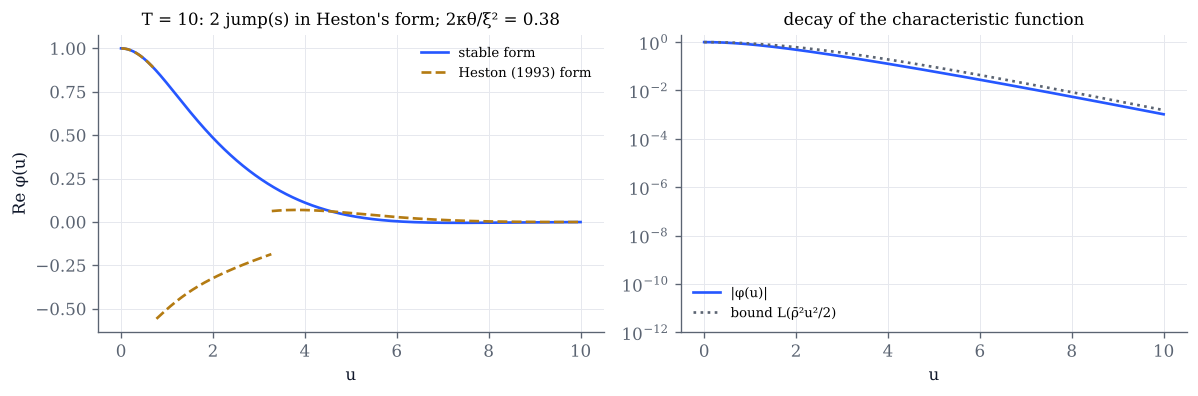

In [2]:
def branch(T=10.0, xi=0.5751, rho=-0.5711, kappa=1.5768):
    p = dict(H.FO, xi=xi, rho=rho, kappa=kappa)
    u = np.linspace(0.0, 10.0, 2001)
    a = H.charfn(u, 1.0, T, 0.0, 0.0, **p)
    b = H.charfn(u, 1.0, T, 0.0, 0.0, form="heston", **p)
    bb = b.real.copy(); bb[1:][np.abs(np.diff(b)) > 0.05] = np.nan
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(u, a.real, color=COBALT, label="stable form")
    ax.plot(u, bb, color=GOLD, ls="--", label="Heston (1993) form")
    jumps = int(np.sum(np.abs(np.diff(b)) > 0.05))
    ax.set(xlabel="u", ylabel="Re φ(u)", title=f"T = {T:g}: {jumps} jump(s) in Heston's form; 2κθ/ξ² = {2*kappa*p['theta']/xi**2:.2f}")
    ax.legend(fontsize=8)
    L = H.laplace_integrated_variance(0.5 * (1 - rho**2) * u**2, T, p["v0"], kappa, p["theta"], xi)
    bx.semilogy(u, np.abs(a), color=COBALT, label="|φ(u)|")
    bx.semilogy(u, L, color=GREY, ls=":", label="bound L(ρ̄²u²/2)")
    bx.set(xlabel="u", ylim=(1e-12, 2), title="decay of the characteristic function")
    bx.legend(fontsize=8); fig.tight_layout(); plt.show()

branch()

In [3]:
# Explore: at which maturity does Heston's form first jump? What happens when 2κθ/ξ² is close to an integer?
# Move ρ towards ±1: what happens to the decay of |φ|?
interact(branch,
         T=FloatSlider(value=10.0, min=0.5, max=30.0, step=0.5, continuous_update=False, description="T"),
         xi=FloatSlider(value=0.5751, min=0.1, max=1.5, step=0.05, continuous_update=False, description="ξ"),
         rho=FloatSlider(value=-0.5711, min=-0.99, max=0.99, step=0.05, continuous_update=False, description="ρ"),
         kappa=FloatSlider(value=1.5768, min=0.2, max=5.0, step=0.1, continuous_update=False, description="κ"));

## 2. Three Fourier inversions

Proposition 19.7: Gil-Pelaez (Heston's $P_1$, $P_2$), Carr and Madan's damped transform, and the COS expansion, here
for the at-the-money put against the number of nodes $N$, as in Figure 19.1(b). Gil-Pelaez and Carr--Madan use the
midpoint rule on $[0,U]$; COS uses the Chernoff interval of the notes. The damping must satisfy
$0<\alpha<a_+(T)-1$ (Theorem 19.5(iv)); the title shows $a_+(T)$. A small damping needs a fine step.

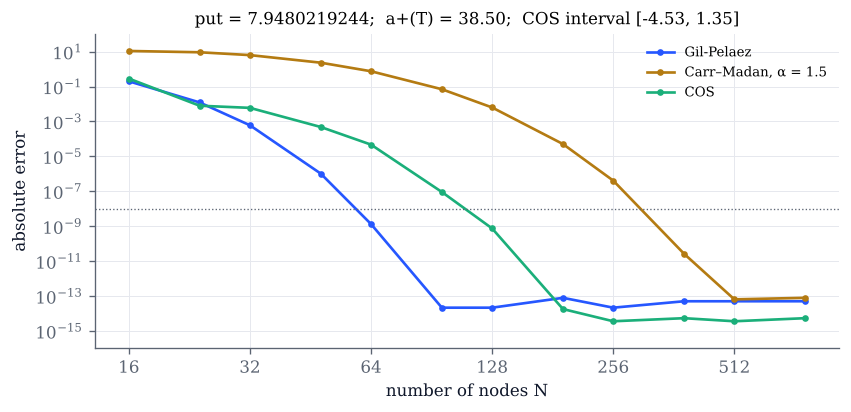

In [4]:
def inversions(rho=-0.7, T=1.0, alpha=1.5, U=125.0):
    p = dict(H.TEST, rho=rho)
    ref = H.price(100.0, S, T, r, y, "put", **p)
    lo, hi = H.cos_interval(S, 100.0, T, r, y, **p)
    ap = H.moment_bound(T, p["kappa"], p["xi"], rho)
    Ns = np.array([16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768])
    gp = [H.gil_pelaez_price(100.0, S, T, r, y, "put", h=U / N, n=N, **p) for N in Ns]
    cm = [H.carr_madan_price(100.0, S, T, r, y, "put", alpha=alpha, h=U / N, n=N, **p) for N in Ns]
    co = [H.cos_price(100.0, S, T, r, y, "put", N=N, interval=(lo, hi), **p) for N in Ns]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for vals, c, name in ((gp, COBALT, "Gil-Pelaez"), (cm, GOLD, f"Carr–Madan, α = {alpha:g}"), (co, GREEN, "COS")):
        ax.loglog(Ns, np.maximum(np.abs(np.array(vals) - ref), 1e-16), color=c, marker="o", ms=3, label=name)
    ax.axhline(1e-8, color=GREY, ls=":", lw=0.8)
    ax.set(xlabel="number of nodes N", ylabel="absolute error", ylim=(1e-16, 1e2),
           title=f"put = {ref:.10f};  a+(T) = {ap:.2f};  COS interval [{lo:.2f}, {hi:.2f}]")
    ax.set_xticks([16, 32, 64, 128, 256, 512]); ax.set_xticklabels(["16", "32", "64", "128", "256", "512"])
    ax.minorticks_off()
    ax.legend(fontsize=8); plt.show()

inversions()

In [5]:
# Explore: try α = 0.5, 1.5, a quarter of a+(T) − 1, and values beyond a+(T) − 1. Shorten T to 0.05: which method
# suffers, and why (look at the decay of φ in section 1)?
interact(inversions,
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.5, step=0.05, continuous_update=False, description="ρ"),
         T=FloatSlider(value=1.0, min=0.05, max=10.0, step=0.05, continuous_update=False, description="T"),
         alpha=FloatSlider(value=1.5, min=0.25, max=20.0, step=0.25, continuous_update=False, description="α"),
         U=FloatSlider(value=125.0, min=25.0, max=400.0, step=25.0, continuous_update=False, description="U"));

## 3. Smiles

Implied volatilities of Heston prices (out-of-the-money options, COS method), as in Figure 19.3. The correlation sets
the skew, $\xi$ the curvature, and $\kappa$ how fast both fade with maturity. The dotted line is $\sqrt{V_0}$. The title
compares the at-the-money skew $\partial\sigma/\partial\ln K$ with the short-maturity heuristic $\rho\xi/(4\sqrt{V_0})$.

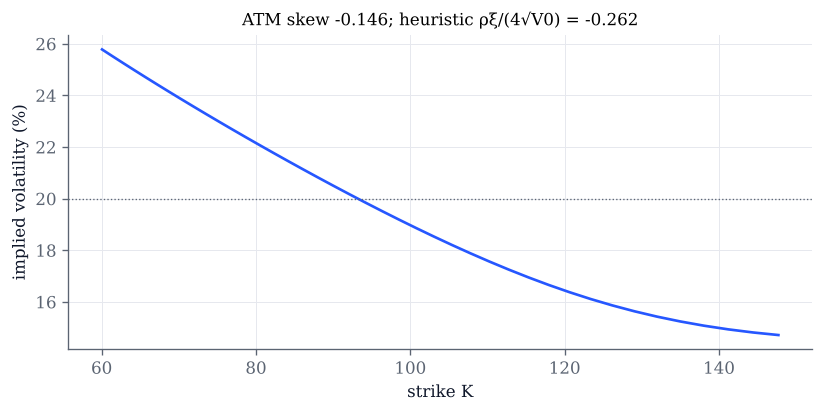

In [6]:
def smile(v0=0.04, kappa=2.0, theta=0.04, xi=0.3, rho=-0.7, T=1.0):
    p = dict(v0=v0, kappa=kappa, theta=theta, xi=xi, rho=rho)
    F = S * np.exp((r - y) * T)
    sd = np.sqrt(max(v0, theta) * T)
    Ks = F * np.exp(np.linspace(-2.5, 2.0, 41) * sd)
    iv = H.implied_vols(Ks, S, T, r, y, **p)
    k = 0.01 * np.sqrt(T)
    iv2 = H.implied_vols(F * np.exp(np.array([-k, k])), S, T, r, y, **p)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(Ks, 100 * iv, color=COBALT)
    ax.axhline(100 * np.sqrt(v0), color=GREY, ls=":", lw=0.8)
    ax.set(xlabel="strike K", ylabel="implied volatility (%)",
           title=f"ATM skew {(iv2[1] - iv2[0]) / (2 * k):.3f}; heuristic ρξ/(4√V0) = {rho * xi / (4 * np.sqrt(v0)):.3f}")
    plt.show()

smile()

In [7]:
# Explore: flip the sign of ρ; raise ξ; raise κ at fixed T; shrink T to 0.02 and compare the skew with the heuristic.
interact(smile,
         v0=FloatSlider(value=0.04, min=0.005, max=0.16, step=0.005, continuous_update=False, description="V0"),
         kappa=FloatSlider(value=2.0, min=0.2, max=10.0, step=0.2, continuous_update=False, description="κ"),
         theta=FloatSlider(value=0.04, min=0.005, max=0.16, step=0.005, continuous_update=False, description="θ"),
         xi=FloatSlider(value=0.3, min=0.05, max=1.5, step=0.05, continuous_update=False, description="ξ"),
         rho=FloatSlider(value=-0.7, min=-0.95, max=0.95, step=0.05, continuous_update=False, description="ρ"),
         T=FloatSlider(value=1.0, min=0.02, max=5.0, step=0.02, continuous_update=False, description="T"));

## 4. Simulation bias: full truncation against QE

Left: bias of the at-the-money put against its Fourier price, for full truncation (log-Euler for $S$,
Proposition 19.8) and Andersen's QE scheme (Proposition 19.9), with the conditional estimator; error bars are two
standard errors. The forward is used as a control variate when the scheme reproduces it exactly (always for full
truncation, for QE only with the martingale correction). The paths here are fewer than in Figure 19.2, so
differences of a few hundredths at the smallest steps are noise.
Right: what the martingale correction removes, computed exactly from Proposition 19.9(iv): the relative error
$\mathbb E[\hat S_{t+h}\mid v]/(\hat S_te^{(r-y)h})-1$ of one uncorrected QE step, against the current variance $v$.

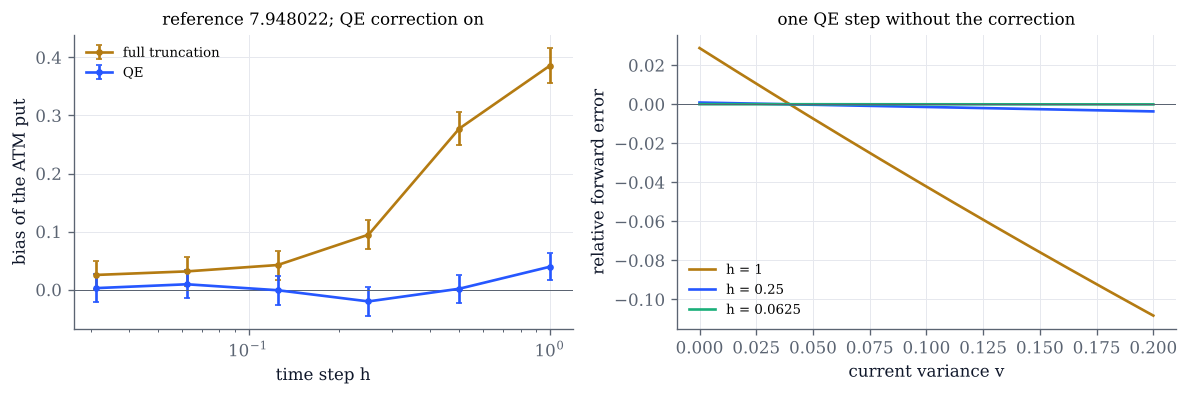

In [8]:
CASES = {"test case, ρ = −0.7": dict(H.TEST, rho=-0.7), "κ = 0.5, ξ = 1, ρ = −0.9": H.CASE_I}

def one_step_forward_error(v, h, p):
    K0, K1, K2, K3, K4 = H.andersen_k(h, p["kappa"], p["theta"], p["xi"], p["rho"])
    q = H.qe_parameters(v, h, p["kappa"], p["theta"], p["xi"])
    k0star = H.martingale_k0(q, v, K1, K2, K3, K4)
    return np.exp(K0 - k0star) - 1.0          # exp(K0 + (K1 + K3/2) v) M - 1

def bias(case="test case, ρ = −0.7", log2_n=15, martingale=True, seed=19):
    p = CASES[case]
    ref = H.price(100.0, S, 1.0, r, y, "put", **p)
    ms = np.array([1, 2, 4, 8, 16, 32])
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    for j, (sch, c, name) in enumerate((("euler", GOLD, "full truncation"), ("qe", COBALT, "QE"))):
        b, s = [], []
        for i, m in enumerate(ms):
            sim = H.simulate(S, 100.0, 1.0, r, y, int(m), 2**log2_n, sch, martingale=martingale, seed=[seed, i, j], **p)
            est, se = H.estimate(sim, S, control=(sch == "euler" or martingale))
            b.append(est - ref); s.append(se)
        ax.errorbar(1 / ms, b, yerr=2 * np.array(s), color=c, marker="o", ms=3, capsize=2, label=name)
    ax.axhline(0, color=GREY, lw=0.6)
    ax.set(xscale="log", xlabel="time step h", ylabel="bias of the ATM put",
           title=f"reference {ref:.6f}; QE correction {'on' if martingale else 'off'}")
    ax.legend(fontsize=8)
    v = np.linspace(0.0, 0.2, 201)
    for h, c in ((1.0, GOLD), (0.25, COBALT), (1 / 16, GREEN)):
        bx.plot(v, one_step_forward_error(v, h, p), color=c, label=f"h = {h:g}")
    bx.axhline(0, color=GREY, lw=0.6)
    bx.set(xlabel="current variance v", ylabel="relative forward error", title="one QE step without the correction")
    bx.legend(fontsize=8); fig.tight_layout(); plt.show()

bias()

In [9]:
# Explore: switch to the second case (Feller's condition badly violated). Switch the martingale correction off:
# does the put bias change visibly? Compare the size of the forward error on the right with the standard errors.
interact(bias,
         case=Dropdown(options=list(CASES), value="test case, ρ = −0.7", description="case"),
         log2_n=IntSlider(value=15, min=12, max=17, continuous_update=False, description="log2 n"),
         martingale=Checkbox(value=True, description="martingale correction"),
         seed=IntSlider(value=19, min=0, max=1000, continuous_update=False, description="seed"));

## Things to try

- In section 1, find the shortest maturity at which Heston's form jumps for the default parameters; then move $\xi$
  towards $\sqrt{2\kappa\theta}\approx0.354$, where $2\kappa\theta/\xi^2=1$, and watch the jumps shrink (Remark 19.6).
- In section 2, set $T=0.05$: the characteristic function decays slowly, so which parameter, $U$ or $N$, limits the
  accuracy of Gil-Pelaez's formula?
- In section 2, with $\rho=0.5$ and $T=10$, read $a_+(T)$ from the title and try a damping just below and just above
  $a_+(T)-1$.
- In section 3, compare the skew at $T=0.02$ with the heuristic for several $\xi$ and $\rho$. When does it fail?
- In section 4, in the second case, how many time steps does full truncation need to match QE with one step per year?